In [5]:
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers

In [6]:
def load_data():
    (x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
    
    return x_train_full, y_train_full , x_test, y_test

In [7]:
x_train_full, y_train_full, x_test, y_test = load_data()

In [8]:
def  normalize_data(x_train_full, x_test):
    MAX_INTENSITY = 255.0
    x_train_full = x_train_full.astype("float32") / MAX_INTENSITY
    x_test = x_test.astype("float32") / MAX_INTENSITY

    return x_train_full, x_test

In [9]:
x_train_full, x_test = normalize_data(x_train_full, x_test)

In [10]:
print(x_train_full.min())
print(x_train_full.max())

print(x_test.min())
print(x_test.max())

0.0
1.0
0.0
1.0


In [11]:
def split_data(x_train_full, y_train_full):
    N_TRAIN = 50_000
    x_val, y_val = x_train_full[N_TRAIN:], y_train_full[N_TRAIN:]
    x_train, y_train = x_train_full[:N_TRAIN], y_train_full[:N_TRAIN]
    
    return x_train, y_train, x_val, y_val

In [12]:
x_train, y_train, x_val, y_val = split_data(x_train_full, y_train_full)


In [13]:
CLASS_NAMES = ["T-shirt", "Trouser", "Pullover", 
               "Dress", "Coat", "Sandal", "Shirt", 
               "Sneaker", "Bag", "Ankle boot"]

In [14]:
print(f"train: {x_train.shape}, val: {x_val.shape}, test: {x_test.shape}, class: {len(CLASS_NAMES)}")

train: (50000, 28, 28), val: (10000, 28, 28), test: (10000, 28, 28), class: 10


In [15]:
def show_plot(x_train, y_train):
    fig, axes = plt.subplots(2, 8, figsize=(12, 4))
    for ax, img, label in zip(axes.flat, x_train, y_train):
        ax.imshow(img, cmap="gray")
        ax.set_title(CLASS_NAMES[label], fontsize=9)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

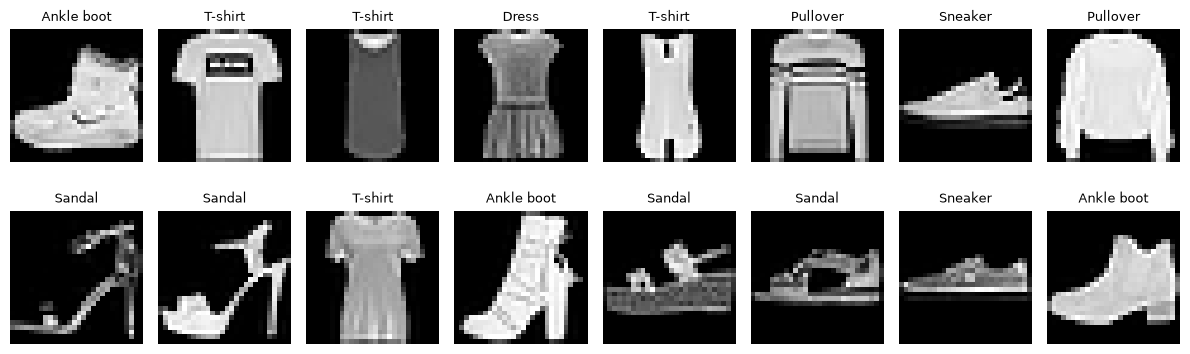

In [16]:
show_plot(x_train, y_train)

In [17]:
import tensorflow as tf

CNN

In [18]:
cnn_model_1 = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(16, 3, activation="relu"),
    layers.Conv2D(32, 3, activation="relu"), 
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.1),
    layers.Dense(32, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(10, activation="softmax")
])

cnn_model_1.compile(optimizer="adam",
                    loss="sparse_categorical_crossentropy",
                    metrics=["accuracy"])

cnn_model_1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 10, 10, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,618 (393.04 KB)

 Trainable params: 100,618 (393.04 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
hist_cnn_model_1 = cnn_model_1.fit(x_train, y_train, validation_split=0.2, epochs=20, batch_size=32)

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/step - accuracy: 0.7501 - loss: 0.6509 - val_accuracy: 0.8279 - val_loss: 0.4577
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 19s 15ms/step - accuracy: 0.8587 - loss: 0.3850 - val_accuracy: 0.8753 - val_loss: 0.3408
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 22s 18ms/step - accuracy: 0.8828 - loss: 0.3202 - val_accuracy: 0.8932 - val_loss: 0.2963
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 18s 14ms/step - accuracy: 0.8989 - loss: 0.2798 - val_accuracy: 0.8981 - val_loss: 0.2842
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 21s 17ms/step - accuracy: 0.9065 - loss: 0.2527 - val_accuracy: 0.9017 - val_loss: 0.2719
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 20s 16ms/step - accuracy: 0.9152 - loss: 0.2303 - val_accuracy: 0.9056 - val_loss: 0.2541
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 17s 13ms/step - accuracy: 0.9204 - loss: 0.2120 - val_accuracy: 0.8997 - val_loss: 0.2795
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - accuracy: 0.9259 -

In [20]:
cnn_model_2 = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(16, 3, activation="relu"),
    layers.Conv2D(32, 3, activation="relu"), 
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.1),
    layers.Dense(32, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(10, activation="softmax")
])

cnn_model_2.compile(optimizer="sgd",
                    loss="sparse_categorical_crossentropy",
                    metrics=["accuracy"])

In [21]:
hist_cnn_model_2 = cnn_model_2.fit(x_train, y_train, validation_split=0.2, epochs=20, batch_size=32)

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 17s 13ms/step - accuracy: 0.4654 - loss: 1.4649 - val_accuracy: 0.6700 - val_loss: 0.8229
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - accuracy: 0.7168 - loss: 0.7400 - val_accuracy: 0.7673 - val_loss: 0.6095
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 17s 13ms/step - accuracy: 0.7710 - loss: 0.6040 - val_accuracy: 0.8055 - val_loss: 0.5126
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - accuracy: 0.8009 - loss: 0.5304 - val_accuracy: 0.8208 - val_loss: 0.4802
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 17s 13ms/step - accuracy: 0.8165 - loss: 0.4913 - val_accuracy: 0.8380 - val_loss: 0.4381
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - accuracy: 0.8317 - loss: 0.4558 - val_accuracy: 0.8442 - val_loss: 0.4314
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 17s 14ms/step - accuracy: 0.8418 - loss: 0.4317 - val_accuracy: 0.8529 - val_loss: 0.4024
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 17s 13ms/step - accuracy: 0.8507 -

In [22]:
cnn_model_3 = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(16, 3, activation="leaky_relu"),
    layers.Conv2D(32, 3, activation="leaky_relu"), 
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="leaky_relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="leaky_relu"),
    layers.Flatten(),
    layers.Dense(64, activation="leaky_relu"),
    layers.Dropout(0.1),
    layers.Dense(32, activation="leaky_relu"),
    layers.Dense(32, activation="leaky_relu"),
    layers.Dense(10, activation="softmax")
])

cnn_model_3.compile(optimizer="adam",
                    loss="sparse_categorical_crossentropy",
                    metrics=["accuracy"])

In [23]:
hist_cnn_model_3 = cnn_model_3.fit(x_train, y_train, validation_split=0.2, epochs=20, batch_size=32)

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/step - accuracy: 0.7785 - loss: 0.5891 - val_accuracy: 0.8492 - val_loss: 0.4085
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 18s 15ms/step - accuracy: 0.8686 - loss: 0.3614 - val_accuracy: 0.8752 - val_loss: 0.3393
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 18s 14ms/step - accuracy: 0.8897 - loss: 0.3033 - val_accuracy: 0.8937 - val_loss: 0.2945
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 19s 15ms/step - accuracy: 0.9006 - loss: 0.2708 - val_accuracy: 0.8994 - val_loss: 0.2870
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 18s 15ms/step - accuracy: 0.9122 - loss: 0.2399 - val_accuracy: 0.9032 - val_loss: 0.2808
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 19s 15ms/step - accuracy: 0.9192 - loss: 0.2188 - val_accuracy: 0.9072 - val_loss: 0.2643
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 17s 14ms/step - accuracy: 0.9255 - loss: 0.2011 - val_accuracy: 0.9087 - val_loss: 0.2609
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 18s 14ms/step - accuracy: 0.9310 -

In [24]:
cnn_model_4 = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(16, 3, activation="leaky_relu"),
    layers.Conv2D(32, 3, activation="leaky_relu"), 
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="leaky_relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="leaky_relu"),
    layers.Flatten(),
    layers.Dense(64, activation="leaky_relu"),
    layers.Dropout(0.1),
    layers.Dense(32, activation="leaky_relu"),
    layers.Dense(32, activation="leaky_relu"),
    layers.Dense(10, activation="softmax")
])

cnn_model_4.compile(optimizer="sgd",
                    loss="sparse_categorical_crossentropy",
                    metrics=["accuracy"])

In [25]:
hist_cnn_model_4 = cnn_model_4.fit(x_train, y_train, validation_split=0.2, epochs=20, batch_size=32)

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 18s 14ms/step - accuracy: 0.5300 - loss: 1.2489 - val_accuracy: 0.7305 - val_loss: 0.6832
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 18s 14ms/step - accuracy: 0.7523 - loss: 0.6397 - val_accuracy: 0.7910 - val_loss: 0.5436
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 18s 14ms/step - accuracy: 0.7976 - loss: 0.5341 - val_accuracy: 0.8234 - val_loss: 0.4775
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 17s 14ms/step - accuracy: 0.8221 - loss: 0.4778 - val_accuracy: 0.8317 - val_loss: 0.4434
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 18s 15ms/step - accuracy: 0.8400 - loss: 0.4367 - val_accuracy: 0.8474 - val_loss: 0.4112
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 17s 14ms/step - accuracy: 0.8508 - loss: 0.4067 - val_accuracy: 0.8566 - val_loss: 0.3914
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 18s 14ms/step - accuracy: 0.8587 - loss: 0.3855 - val_accuracy: 0.8663 - val_loss: 0.3634
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 17s 14ms/step - accuracy: 0.8677 -

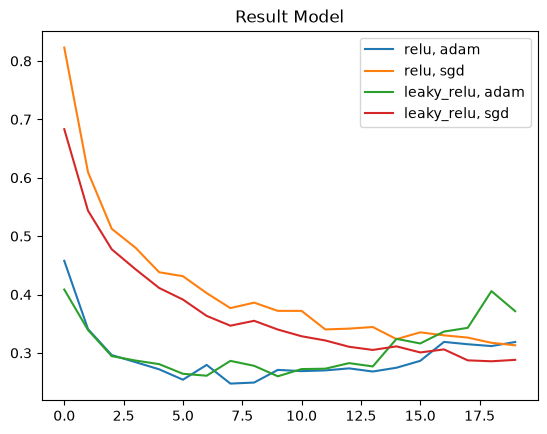

In [26]:
plt.plot(hist_cnn_model_1.history["val_loss"], label="relu, adam")
plt.plot(hist_cnn_model_2.history["val_loss"], label="relu, sgd")
plt.plot(hist_cnn_model_3.history["val_loss"], label="leaky_relu, adam")
plt.plot(hist_cnn_model_4.history["val_loss"], label="leaky_relu, sgd")
plt.title("Result Model")
plt.legend()
plt.show()